# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('/kaggle/input/datasets/naveenkumar17062002/co2-emissions-csv/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

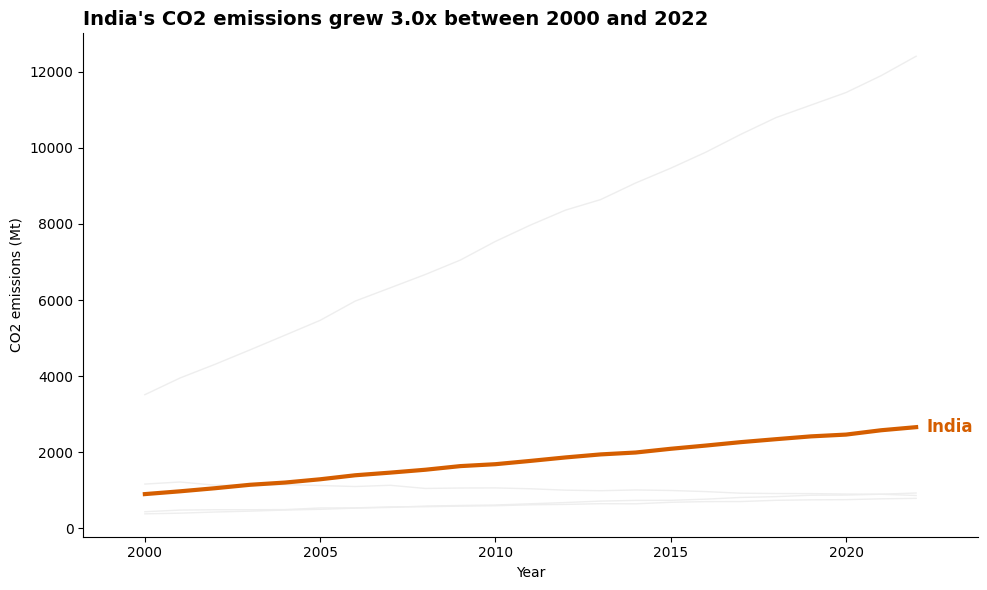

In [3]:
# Task — Multi-series line with highlight
# YOUR CODE HERE
import matplotlib.pyplot as plt

# 1. Keep only Asian countries
asia = df[df["Region"] == "Asia"]

highlight = "India"   # <- your choice, e.g. "China"

fig, ax = plt.subplots(figsize=(10, 6))

# 2. All other countries: thin grey lines for context
for country, g in asia.groupby("Country"):
    if country != highlight:
        g = g.sort_values("Year")
        ax.plot(g["Year"], g["CO2_Mt"], color="#EEEEEE", linewidth=1)

# 3. Highlighted country: coloured, thicker line
h = asia[asia["Country"] == highlight].sort_values("Year")
ax.plot(h["Year"], h["CO2_Mt"], color="#D55E00", linewidth=3)

# 4. Direct label at the end of the line (no legend)
ax.text(h["Year"].iloc[-1] + 0.3, h["CO2_Mt"].iloc[-1], highlight,
        color="#D55E00", fontsize=12, fontweight="bold", va="center")

# 5. Insight title built from the data, so the numbers are always correct
start_year, end_year = h["Year"].iloc[0], h["Year"].iloc[-1]
start_val, end_val = h["CO2_Mt"].iloc[0], h["CO2_Mt"].iloc[-1]
ax.set_title(
    f"{highlight}'s CO2 emissions grew {end_val / start_val:.1f}x "
    f"between {start_year} and {end_year}",
    fontsize=14, fontweight="bold", loc="left"
)

ax.set_xlabel("Year")
ax.set_ylabel("CO2 emissions (Mt)")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.08)   # extra room on the right for the label

plt.tight_layout()
plt.show()